# Zero-shot tumour detection on a TCGA-BRCA slide (`TCGA-AR-A0TP`)

Runs the **existing** pipeline (`scripts/pipeline_lib.py`, unchanged) on a breast-cancer
whole-slide image from TCGA — a different tissue than the CAMELYON16 lymph-node slides,
so the zero-shot text prompts are set for **breast primary carcinoma**.

No annotation exists for this TCGA slide, so the `validate` step is skipped — we produce
the tissue, tiles, spatial-domain and zero-shot tumour/normal maps. Run top-to-bottom.

## 1. Setup (import the library, point at the slide, set breast prompts)

In [1]:
%matplotlib inline
import os, sys
from pathlib import Path
from IPython.display import Image, display

# ==== EDIT THESE ====
SLIDE = os.path.expanduser(
    "~/wsi-shared-slides/TCGA-AR-A0TP-01Z-00-DX1.58E6A3A6-D1D7-4AE5-87A5-E823F04CBB2F.svs")
MODEL = "plip"       # vision+language model for zero-shot ("plip" open, "conch" gated)
OUT   = "outputs"
# ====================

# find the repo root (folder with scripts/pipeline_lib.py) and make it importable
here = Path.cwd()
REPO = next((p for p in [here, *here.parents] if (p / "scripts" / "pipeline_lib.py").exists()), here)
os.chdir(REPO); sys.path.insert(0, str(REPO / "scripts"))
import pipeline_lib as pl

# breast-primary prompts (the library defaults are lymph-node specific)
cfg = pl.Config(model=MODEL, classes={
    "tumor":  "invasive breast carcinoma, malignant epithelial tumor cells",
    "normal": "normal breast tissue, benign stroma and adipose tissue",
})
slide = Path(SLIDE)

def show(*names):
    for n in names:
        p = Path(OUT) / f"{slide.stem}_{n}.png"
        display(Image(str(p))) if p.exists() else print(f"(no {p.name})")

print(f"slide       : {slide.name}   (exists: {slide.exists()})")
print(f"model / amp : {cfg.model} / {cfg.amp}")
print(f"prompts     : {cfg.classes}")
print("ready — run the stage cells below.")

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


slide       : TCGA-AR-A0TP-01Z-00-DX1.58E6A3A6-D1D7-4AE5-87A5-E823F04CBB2F.svs   (exists: True)
model / amp : plip / True
prompts     : {'tumor': 'invasive breast carcinoma, malignant epithelial tumor cells', 'normal': 'normal breast tissue, benign stroma and adipose tissue'}
ready — run the stage cells below.


## 2. Preprocess (detect tissue, cut into tiles)

opened TCGA-AR-A0TP-01Z-00-DX1.58E6A3A6-D1D7-4AE5-87A5-E823F04CBB2F: [83190, 75208]  mpp=0.247
tissue pieces: 3
tiles: 10446
[preprocess] saved -> outputs/TCGA-AR-A0TP-01Z-00-DX1.58E6A3A6-D1D7-4AE5-87A5-E823F04CBB2F.zarr


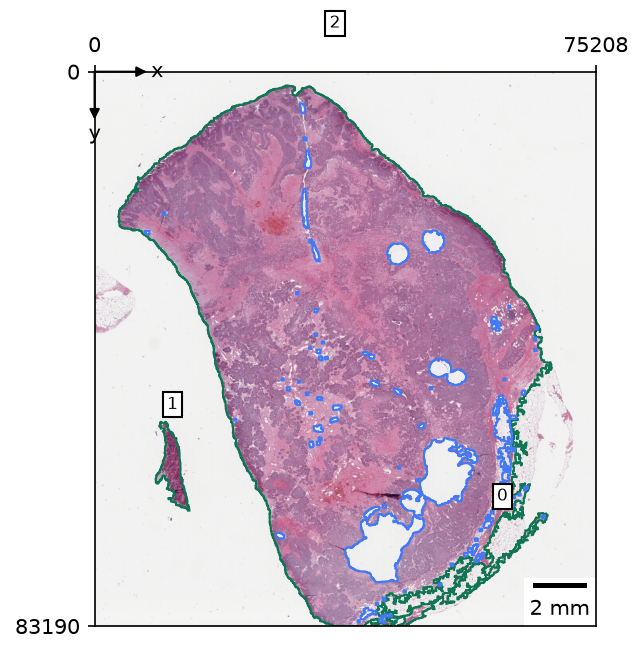

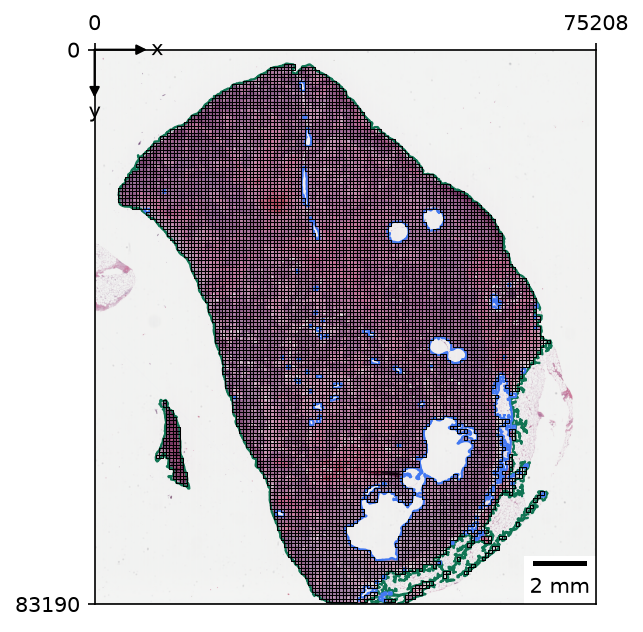

In [2]:
pl.preprocess(str(slide), cfg, OUT)
show("tissue", "tiles")

## 3. Features (PLIP tile features + spatial domains)

tiles: 10446
reusing existing plip features
spatial domains: 8
[features] plip features + domains saved


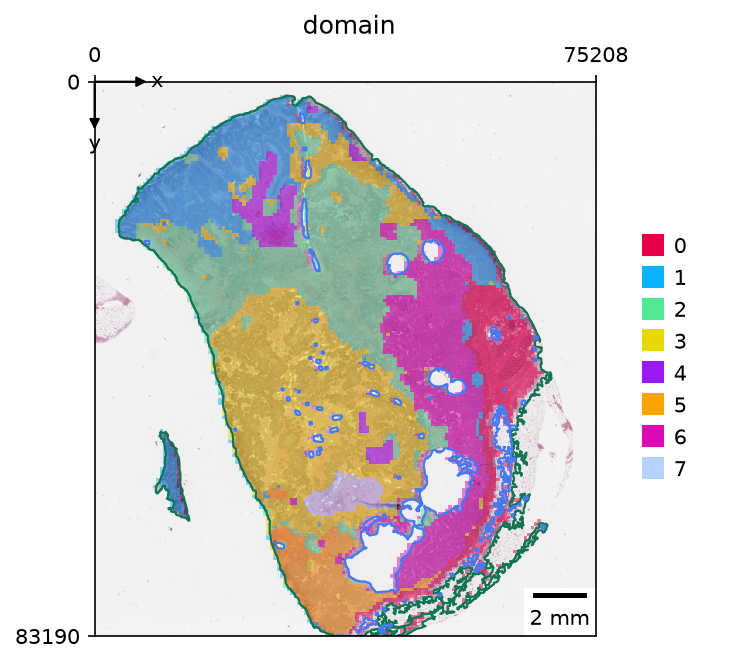

In [3]:
pl.features(str(slide), cfg, OUT)
show("domains")

## 4. Zero-shot (training-free breast-tumour score)

zero-shot model: plip


/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/lazyslide_models/multimodal/plip.py:27: UserWarning: As from v0.8.2, Normalization will not be applied to image embedding of PLIP model anymore.A `normalize=True` argument is added to the `text_image_similarity` method.If you only use the image embedding for text image similarity, you can safely ignore this warning.
  warnings.warn(
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 58599.82it/s]
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/lazyslide/tools/_text_annotate.py:169: UserWarning: As of v0.8.2, the image embedding from image text model is not normalized after feature extraction by default. The normalization is applied here (text_image_similarity),if your features are extracted in previous versions, consider setting normalize=False.
  warnings.warn(msg, stacklevel=find_stack_level())


[zero_shot] scores saved -> table 'zeroshot'


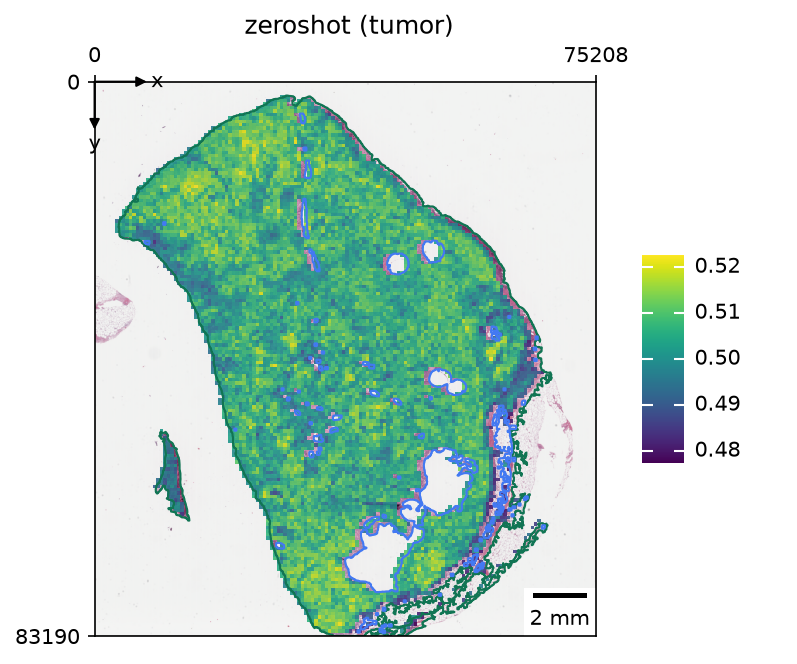

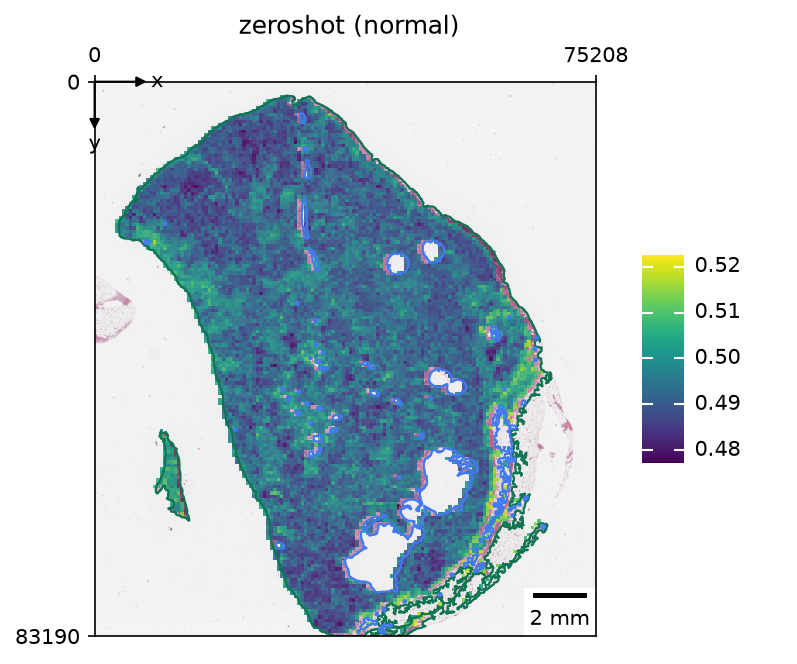

In [4]:
pl.zero_shot(str(slide), cfg, OUT)
show("zeroshot_tumor", "zeroshot_normal")

## 5. Validate — skipped

This TCGA slide has no pixel-level annotation next to it, so `pl.validate()` returns
`None` and there is no ROC-AUC. (The CAMELYON16 slides in `slides/` *do* have `.xml`
annotations and can be validated with the main `pipeline.ipynb`.)